# EDAV Course-End Project: Digital Marketing Campaign Analysis

**Course:** EDAV (22ADC32N)  
**Project Title:** Digital Marketing Campaign Analysis

## Objective
Analyze digital marketing campaign data using NumPy, Pandas, Matplotlib, and Seaborn to understand campaign performance across channels and campaign types. The project examines impressions, clicks, conversions, advertising spend, revenue, and return on advertising spend.

## Dataset note
The accompanying `digital_marketing_campaign_dataset.csv` contains digital marketing campaign performance data covering multiple marketing channels and campaign types. The dataset includes key performance indicators such as impressions, clicks, conversions, advertising spend, and return on investment (ROI). It supports the analysis of campaign effectiveness, channel-wise performance, customer engagement, and marketing expenditure. The dataset also includes a small number of missing values and duplicate records to support data cleaning, preprocessing, and data quality assessment before conducting further analysis.

## Environment setup
Run this notebook in Google Colab or Jupyter Notebook. Upload `digital_marketing_campaign_dataset.csv` to the notebook's working directory.

Recommended libraries: `numpy`, `pandas`, `matplotlib`, and `seaborn`.


## Import libraries
**Concept explanation:** NumPy supports numerical operations, Pandas helps clean and summarize tabular data, and Matplotlib/Seaborn create visualizations.

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## Load and inspect the dataset
**Concept explanation:** Check sample rows, data types, missing values, and duplicate records before performing analysis.

In [66]:
df = pd.read_csv("digital_marketing_campaign_dataset.csv")

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())


First five rows:


,Date,Campaign,Channel,Campaign_Type,Spend,Impressions,Clicks,Conversions,Revenue
0,2026-08-01,Social Media - Awareness,Social Media,Awareness,218.54,10475,336.0,4,92.26
1,2026-08-01,Social Media - Traffic,Social Media,Traffic,180.65,8097,246.0,5,222.90
2,2026-08-01,Social Media - Lead Generation,Social Media,Lead Generation,100.31,11690,284.0,30,2157.29
3,2026-08-01,Social Media - Sales,Social Media,Sales,NaN,12555,440.0,27,2614.51
4,2026-08-01,Search Ads - Awareness,Search Ads,Awareness,218.38,14054,667.0,10,371.62


Dataset shape: (723, 9)
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 723 entries, 0 to 722
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           723 non-null    object 
 1   Campaign       723 non-null    object 
 2   Channel        718 non-null    object 
 3   Campaign_Type  723 non-null    object 
 4   Spend          718 non-null    float64
 5   Impressions    723 non-null    int64  
 6   Clicks         718 non-null    float64
 7   Conversions    723 non-null    int64  
 8   Revenue        718 non-null    float64
dtypes: float64(3), int64(2), object(4)
memory usage: 51.0+ KB
\nMissing values by column:


,Missing values
Date,0
Campaign,0
Channel,5
Campaign_Type,0
Spend,5
Impressions,0
Clicks,5
Conversions,0
Revenue,5


Duplicate rows: 3


## Q1. Apply NumPy to calculate average, minimum, and maximum clicks by marketing channel
**Concept explanation:** NumPy functions such as `mean()`, `min()`, and `max()` summarize numeric values. Missing click values are excluded temporarily before calculations.

**Goal:** Compare click activity across channels and understand the range of observed clicks.

In [72]:
# Overall click statistics, excluding missing values
clicks_array = df["Clicks"].dropna().to_numpy()

print("Average clicks:", round(np.mean(clicks_array), 2))
print("Minimum clicks:", int(np.min(clicks_array)))
print("Maximum clicks:", int(np.max(clicks_array)))

# Click statistics for each channel
for channel in sorted(df["Channel"].dropna().unique()):
    values = df.loc[df["Channel"] == channel, "Clicks"].dropna().to_numpy()
    print(f"\\n{channel}")
    print("Average clicks:", round(np.mean(values), 2))
    print("Minimum clicks:", int(np.min(values)))
    print("Maximum clicks:", int(np.max(values)))


Average clicks: 421.98
Minimum clicks: 32
Maximum clicks: 1280
\nDisplay Ads
Average clicks: 111.59
Minimum clicks: 32
Maximum clicks: 215
\nEmail
Average clicks: 589.51
Minimum clicks: 279
Maximum clicks: 1280
\nSearch Ads
Average clicks: 640.95
Minimum clicks: 289
Maximum clicks: 1116
\nSocial Media
Average clicks: 347.59
Minimum clicks: 132
Maximum clicks: 649


**Conclusion/insight:** Compare average clicks across channels to identify which channel generates more click activity in this dataset. Minimum and maximum values show the observed range. Click volume alone does not prove campaign profitability; spend and conversions must also be considered.

## Q2. Use Pandas to analyze how marketing channel and campaign type influence performance
**Concept explanation:** `groupby()` and aggregation compare channels and campaign types. Click-through rate (CTR) is clicks divided by impressions, conversion rate is conversions divided by clicks, and return on advertising spend (ROAS) is revenue divided by spend.

These are descriptive measures. A higher value in this dataset does not automatically prove that a channel will perform the same way in every business.

In [68]:
analysis_df = df.copy()

channel_summary = (
    analysis_df.dropna(subset=["Channel"])
    .groupby("Channel")
    .agg(
        Campaign_Records=("Campaign", "count"),
        Spend=("Spend", "sum"),
        Impressions=("Impressions", "sum"),
        Clicks=("Clicks", "sum"),
        Conversions=("Conversions", "sum"),
        Revenue=("Revenue", "sum")
    )
)

channel_summary["CTR (%)"] = 100 * channel_summary["Clicks"] / channel_summary["Impressions"]
channel_summary["Conversion Rate (%)"] = 100 * channel_summary["Conversions"] / channel_summary["Clicks"]
channel_summary["ROAS"] = channel_summary["Revenue"] / channel_summary["Spend"]
display(channel_summary.round(2).sort_values("ROAS", ascending=False))

campaign_type_summary = (
    analysis_df.groupby("Campaign_Type")
    .agg(
        Spend=("Spend", "sum"),
        Clicks=("Clicks", "sum"),
        Conversions=("Conversions", "sum"),
        Revenue=("Revenue", "sum")
    )
)
campaign_type_summary["Conversion Rate (%)"] = 100 * campaign_type_summary["Conversions"] / campaign_type_summary["Clicks"]
campaign_type_summary["ROAS"] = campaign_type_summary["Revenue"] / campaign_type_summary["Spend"]
display(campaign_type_summary.round(2).sort_values("Conversion Rate (%)", ascending=False))


,Campaign_Records,Spend,Impressions,Clicks,Conversions,Revenue,CTR (%),Conversion Rate (%),ROAS
Channel,,,,,,,,,
Search Ads,181,31947.67,2117186,114089.0,5126,349543.04,5.39,4.49,10.94
Email,180,32460.99,1432603,105523.0,4509,308785.70,7.37,4.27,9.51
Social Media,180,31668.47,1748785,62566.0,2686,183098.39,3.58,4.29,5.78
Display Ads,177,32348.95,1107879,19639.0,762,52719.26,1.77,3.88,1.63


,Spend,Clicks,Conversions,Revenue,Conversion Rate (%),ROAS
Campaign_Type,,,,,,
Lead Generation,31841.70,75710.0,5789,366502.93,7.65,11.51
Sales,32416.46,75883.0,4209,402616.49,5.55,12.42
Traffic,32862.16,73028.0,1717,77278.79,2.35,2.35
Awareness,32171.86,78362.0,1388,48476.70,1.77,1.51


**Conclusion/insight:** Use CTR to compare how often impressions lead to clicks, conversion rate to compare how often clicks lead to conversions, and ROAS to compare revenue with advertising spend. Check the printed results before stating which channel or campaign type performed best.

## Q3. Handle missing values and duplicate records
**Concept explanation:** Missing values can distort metrics, and duplicates can cause records to be counted twice. Remove exact duplicate rows, fill missing channel names with `Unknown`, and impute missing numeric values using the median of the relevant channel when possible, falling back to the overall median.

In [69]:
clean_df = df.copy()

# Remove exact duplicate rows
before = len(clean_df)
clean_df = clean_df.drop_duplicates()
print("Duplicate rows removed:", before - len(clean_df))

# Fill missing channel labels
clean_df["Channel"] = clean_df["Channel"].fillna("Unknown")

numeric_columns = ["Spend", "Impressions", "Clicks", "Conversions", "Revenue"]
for col in numeric_columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")
    overall_median = clean_df[col].median()
    clean_df[col] = clean_df.groupby("Channel")[col].transform(
        lambda values: values.fillna(values.median())
    )
    clean_df[col] = clean_df[col].fillna(overall_median)

clean_df["Date"] = pd.to_datetime(clean_df["Date"], errors="coerce")

print("Missing values after cleaning:")
display(clean_df.isna().sum().to_frame("Missing values"))
print("Rows after cleaning:", len(clean_df))
display(clean_df.head())


Duplicate rows removed: 3
Missing values after cleaning:


,Missing values
Date,0
Campaign,0
Channel,0
Campaign_Type,0
Spend,0
Impressions,0
Clicks,0
Conversions,0
Revenue,0


Rows after cleaning: 720


,Date,Campaign,Channel,Campaign_Type,Spend,Impressions,Clicks,Conversions,Revenue
0,2026-08-01,Social Media - Awareness,Social Media,Awareness,218.54,10475,336.0,4,92.26
1,2026-08-01,Social Media - Traffic,Social Media,Traffic,180.65,8097,246.0,5,222.90
2,2026-08-01,Social Media - Lead Generation,Social Media,Lead Generation,100.31,11690,284.0,30,2157.29
3,2026-08-01,Social Media - Sales,Social Media,Sales,180.01,12555,440.0,27,2614.51
4,2026-08-01,Search Ads - Awareness,Search Ads,Awareness,218.38,14054,667.0,10,371.62


**Conclusion/insight:** Removing exact duplicates prevents repeated records from inflating totals. Median imputation allows analysis to continue, but imputed values are estimates and may affect performance metrics. For real campaign reporting, confirm missing data with the original advertising platform whenever possible.

## Q4. Group campaigns by channel and campaign type to compute descriptive statistics
**Concept explanation:** Grouping campaign records by channel and campaign type helps compare cost, traffic, conversions, and revenue. Aggregations such as count, mean, and sum summarize campaign performance.

In [70]:
# Performance summary by channel and campaign type
group_summary = (
    clean_df.groupby(["Channel", "Campaign_Type"])
    .agg(
        Records=("Campaign", "count"),
        Average_Spend=("Spend", "mean"),
        Total_Impressions=("Impressions", "sum"),
        Total_Clicks=("Clicks", "sum"),
        Total_Conversions=("Conversions", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .round(2)
)
display(group_summary)

# Overall daily results
daily_summary = clean_df.groupby("Date").agg(
    Spend=("Spend", "sum"),
    Clicks=("Clicks", "sum"),
    Conversions=("Conversions", "sum"),
    Revenue=("Revenue", "sum")
)
daily_summary["ROAS"] = daily_summary["Revenue"] / daily_summary["Spend"]

print("Top five dates by revenue:")
display(daily_summary.sort_values("Revenue", ascending=False).head(5).round(2))

print("Top channel by total conversions:")
print(clean_df.groupby("Channel")["Conversions"].sum().idxmax())


Records  Average_Spend  Total_Impressions  \
Channel      Campaign_Type                                                
Display Ads  Awareness             45         175.02             285827   
             Lead Generation       44         176.53             279538   
             Sales                 45         191.47             288919   
             Traffic               43         188.13             253595   
Email        Awareness             45         183.48             374815   
             Lead Generation       45         180.17             348317   
             Sales                 45         178.38             375615   
             Traffic               45         183.39             333856   
Search Ads   Awareness             44         182.26             520870   
             Lead Generation       45         178.59             536688   
             Sales                 45         177.12             525219   
             Traffic               45         172.48             514296   
Social Media Awareness             44         175.27             438880   
             Lead Generation       45         180.33             453367   
             Sales                 45         177.22             433025   
             Traffic               45         182.46             412025   
Unknown      Awareness              2         153.91              22521   
             Lead Generation        1         175.13               3666   
             Traffic                2         191.58              12094   

                              Total_Clicks  Total_Conversions  Total_Revenue  
Channel      Campaign_Type                                                    
Display Ads  Awareness              5223.0                 72        2538.42  
             Lead Generation        4819.0                355       21578.34  
             Sales                  5142.0                251       24705.48  
             Traffic                4564.0                 84        3897.02  
Email        Awareness             28817.0                545       19920.10  
             Lead Generation       25979.0               1915      125671.93  
             Sales                 26945.0               1484      140930.02  
             Traffic               24377.0                565       25999.40  
Search Ads   Awareness             28092.0                511       18500.12  
             Lead Generation       29663.0               2287      144049.42  
             Sales                 28952.5               1602      155368.84  
             Traffic               28260.0                693       31364.97  
Social Media Awareness             15332.0                246        8357.23  
             Lead Generation       16470.0               1231       77691.04  
             Sales                 15593.0                848       80472.75  
             Traffic               14792.0                356       16313.13  
Unknown      Awareness               898.0                 14         406.08  
             Lead Generation          48.0                  1          77.91  
             Traffic                 220.0                  5         244.53

Top five dates by revenue:


,Spend,Clicks,Conversions,Revenue,ROAS
Date,,,,,
2026-09-05,2801.51,7682.0,381,26880.57,9.60
2026-08-21,2775.34,7169.0,359,25866.11,9.32
2026-08-14,3187.98,7202.0,374,24341.18,7.64
2026-08-12,2974.89,7620.0,355,24051.31,8.08
2026-08-20,2730.02,7905.0,339,24001.71,8.79


Top channel by total conversions:
Search Ads


**Conclusion/insight:** The grouped summary shows how performance differs by channel and campaign type. The top-revenue dates and channel with the most conversions highlight volume, but should be reviewed alongside advertising spend and ROAS before deciding where to allocate a budget.

## Q5. Create bar plots, line plots, and a heatmap to visualize campaign performance
**Concept explanation:** Bar charts compare categories, line plots show changes over time, and a heatmap helps compare performance across channels and campaign types. All charts include descriptive titles and axis labels.

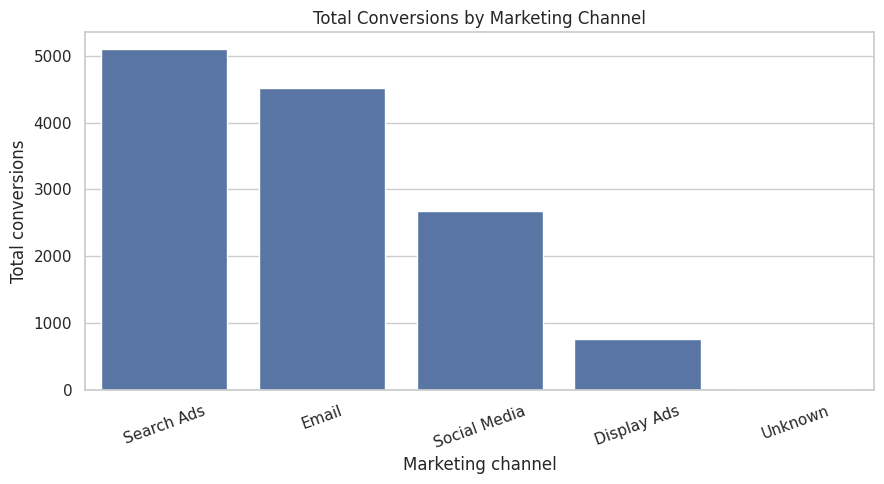

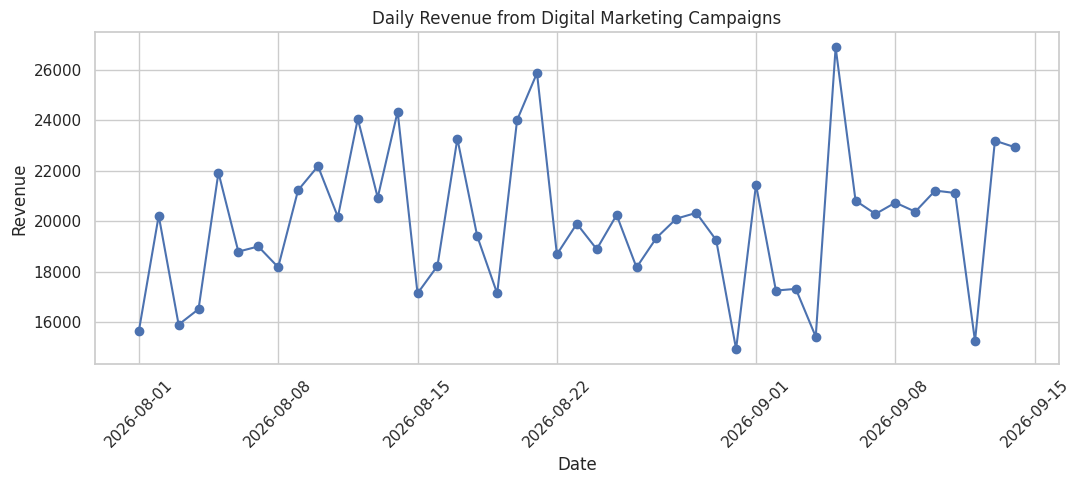

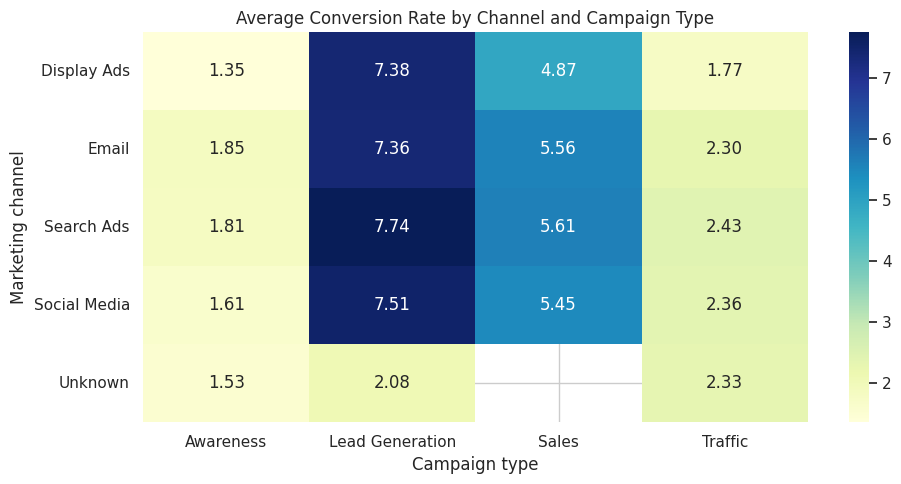

In [71]:
# 1. Bar plot: total conversions by channel
channel_conversions = clean_df.groupby("Channel")["Conversions"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=channel_conversions.index, y=channel_conversions.values)
plt.title("Total Conversions by Marketing Channel")
plt.xlabel("Marketing channel")
plt.ylabel("Total conversions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 2. Line plot: daily revenue
daily_revenue = clean_df.groupby("Date")["Revenue"].sum().sort_index()
plt.figure(figsize=(11, 5))
plt.plot(daily_revenue.index, daily_revenue.values, marker="o")
plt.title("Daily Revenue from Digital Marketing Campaigns")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Heatmap: average conversion rate by channel and campaign type
heat_source = clean_df.copy()
heat_source["Conversion Rate (%)"] = np.where(
    heat_source["Clicks"] > 0,
    100 * heat_source["Conversions"] / heat_source["Clicks"],
    np.nan
)
heat_pivot = heat_source.pivot_table(
    index="Channel",
    columns="Campaign_Type",
    values="Conversion Rate (%)",
    aggfunc="mean"
)

plt.figure(figsize=(10, 5))
sns.heatmap(heat_pivot, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Conversion Rate by Channel and Campaign Type")
plt.xlabel("Campaign type")
plt.ylabel("Marketing channel")
plt.tight_layout()
plt.show()


**Conclusion/insight:** The bar plot compares conversion volume by channel, the line plot shows daily revenue trends, and the heatmap compares average conversion rates across channel and campaign type. Use the actual chart output to describe the strongest and weakest combinations. Avoid claiming that the charts prove causation.

## Overall conclusion
This project demonstrates the use of NumPy and Pandas to clean, summarize, and compare digital marketing campaign data, and the use of Matplotlib and Seaborn to visualize results. Metrics such as CTR, conversion rate, and ROAS provide different views of campaign performance. A campaign with many clicks may not necessarily generate the most revenue or best return.

